# Exploratory Data Analysis - Breast Cancer Wisconsin (Diagnostic) Dataset
### Explainable AI Framework for Medical Diagnosis

This notebook is a lightweight, optional companion to the main project scripts
(`preprocessing.py`, `train_model.py`, `explainability.py`). It is meant for
quickly exploring the dataset and sanity-checking the trained model/SHAP values
interactively, e.g. in Jupyter or VS Code's notebook view.

Run `train_model.py` and `generate_explanations.py` from the project root at
least once before running the later cells of this notebook, since it reuses
their saved outputs (`models/`, `reports/`).


In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))  # so we can import the project's .py modules

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from preprocessing import load_raw_dataframe

sns.set_theme(style='whitegrid')
df = load_raw_dataframe()
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 1. Basic dataset info

In [2]:
print(f"Shape: {df.shape}")
print(f"\nClass balance (1=Malignant, 0=Benign):")
print(df['diagnosis'].value_counts())
df.describe().T

Shape: (569, 31)

Class balance (1=Malignant, 0=Benign):
diagnosis
0    357
1    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## 2. Class distribution

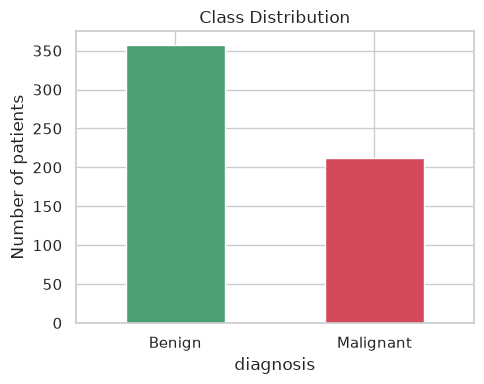

In [3]:
ax = df['diagnosis'].value_counts().rename({0: 'Benign', 1: 'Malignant'}).plot(
    kind='bar', color=['#4C9F70', '#D1495B'], rot=0, figsize=(5,4))
ax.set_ylabel('Number of patients')
ax.set_title('Class Distribution')
plt.tight_layout()
plt.show()

## 3. Feature correlation heatmap (mean-value features)

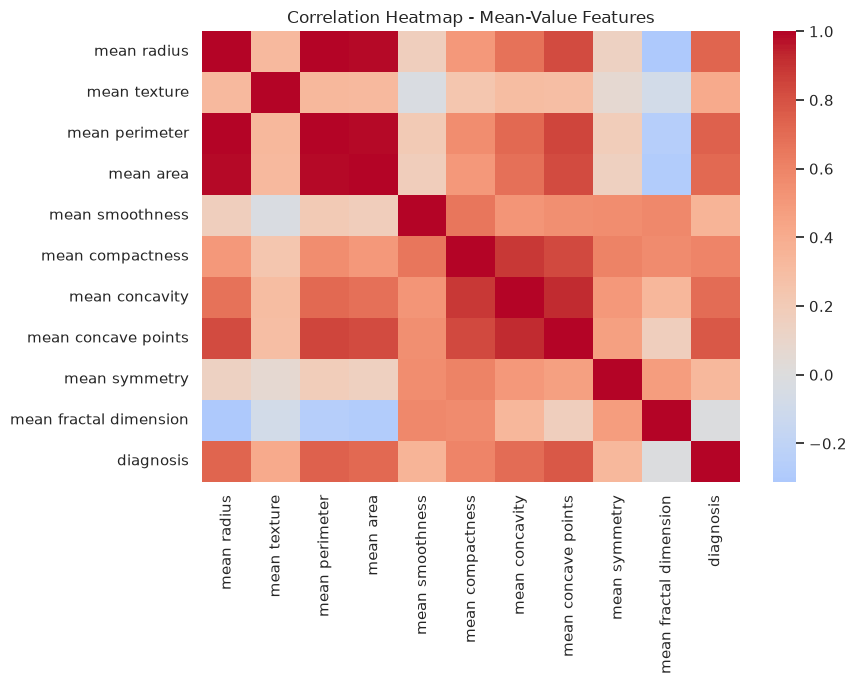

In [4]:
mean_cols = [c for c in df.columns if c.startswith('mean')] + ['diagnosis']
plt.figure(figsize=(9, 7))
sns.heatmap(df[mean_cols].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap - Mean-Value Features')
plt.tight_layout()
plt.show()

## 4. Distribution of a few key features by diagnosis

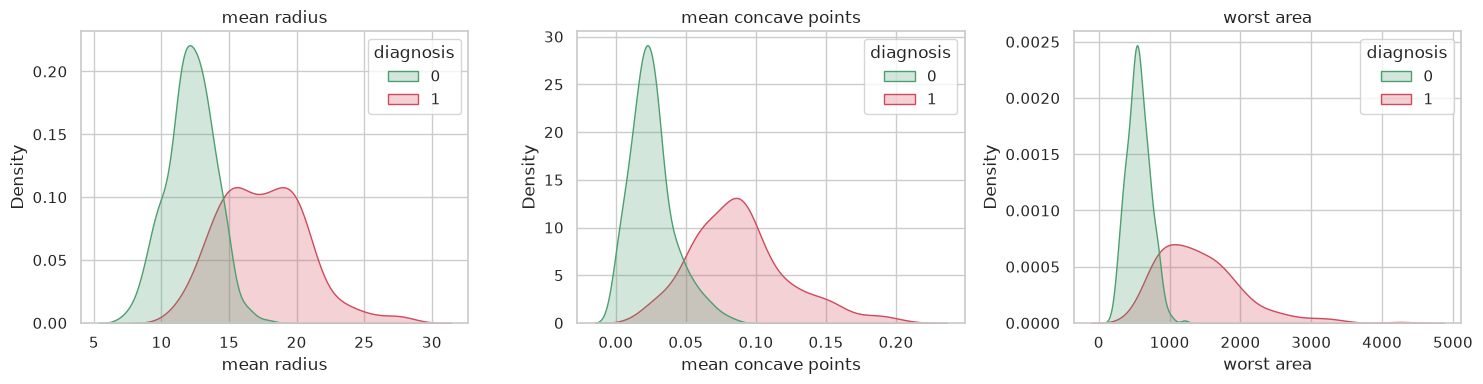

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, ['mean radius', 'mean concave points', 'worst area']):
    sns.kdeplot(data=df, x=feat, hue='diagnosis', fill=True, common_norm=False, ax=ax,
                palette={0: '#4C9F70', 1: '#D1495B'})
    ax.set_title(feat)
plt.tight_layout()
plt.show()

## 5. Loading the trained model + SHAP explainer (after running train_model.py & generate_explanations.py)

In [6]:
import joblib

model = joblib.load('../models/best_model.pkl')
scaler = joblib.load('../models/scaler.pkl')
feature_names = joblib.load('../models/feature_names.pkl')

import json
with open('../models/model_metadata.json') as f:
    metadata = json.load(f)
metadata

{'best_model_name': 'Logistic Regression',
 'class_mapping': {'0': 'Benign', '1': 'Malignant'},
 'selection_criterion': 'Highest ROC-AUC, tie-break by F1-score',
 'all_model_metrics': {'Logistic Regression': {'accuracy': 0.9649122807017544,
   'precision': 0.975,
   'recall': 0.9285714285714286,
   'f1_score': 0.9512195121951219,
   'roc_auc': 0.996031746031746},
  'Random Forest': {'accuracy': 0.9736842105263158,
   'precision': 1.0,
   'recall': 0.9285714285714286,
   'f1_score': 0.9629629629629629,
   'roc_auc': 0.9947089947089947},
  'XGBoost': {'accuracy': 0.9649122807017544,
   'precision': 1.0,
   'recall': 0.9047619047619048,
   'f1_score': 0.95,
   'roc_auc': 0.9930555555555555}},
 'n_train_samples': 455,
 'n_test_samples': 114,
 'n_features': 30,
 'random_state': 42}

## 6. Quick interactive SHAP check on a few test patients

In [7]:
from explainability import build_shap_explainer, compute_shap_values, get_instance_shap

X_train_raw = pd.read_csv('../models/X_train_background.csv')
test_df = pd.read_csv('../models/X_test_sample.csv')
X_test_raw = test_df[feature_names]
y_test = test_df['diagnosis']

X_train_scaled = scaler.transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

explainer = build_shap_explainer(model, pd.DataFrame(X_train_scaled, columns=feature_names))
shap_values = compute_shap_values(explainer, pd.DataFrame(X_test_scaled, columns=feature_names))

import shap
shap.plots.waterfall(shap.Explanation(
    values=get_instance_shap(shap_values, 0)[0],
    base_values=get_instance_shap(shap_values, 0)[1],
    data=X_test_scaled[0],
    feature_names=feature_names,
))

/home/claude/xai-medical-diagnosis/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 7. Summary

This notebook is for exploration only — the reproducible, "official" pipeline
lives in `train_model.py` (training/evaluation) and `generate_explanations.py`
(global SHAP plots + sample explanations), with `app.py` as the user-facing
Streamlit interface. See the project `README.md` for full run instructions.